   Year   Lag1   Lag2   Lag3   Lag4   Lag5    Volume  Today Direction
0  1990  0.816  1.572 -3.936 -0.229 -3.484  0.154976 -0.270      Down
1  1990 -0.270  0.816  1.572 -3.936 -0.229  0.148574 -2.576      Down
2  1990 -2.576 -0.270  0.816  1.572 -3.936  0.159837  3.514        Up
3  1990  3.514 -2.576 -0.270  0.816  1.572  0.161630  0.712        Up
4  1990  0.712  3.514 -2.576 -0.270  0.816  0.153728  1.178        Up


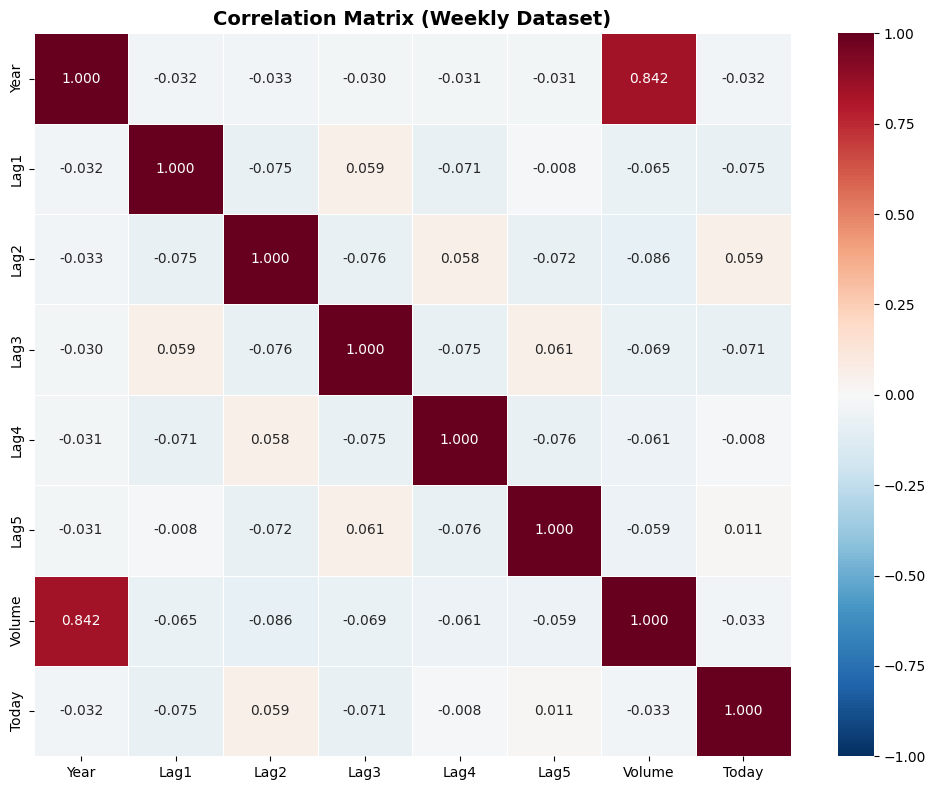


--- Preparing Data for Boosted Model (LightGBM) ---
Training LightGBM Boosted Model...

Boosted Model (LightGBM) Validation Accuracy: 0.5321

--- Classification Report ---
              precision    recall  f1-score   support

        Down       0.47      0.43      0.45        97
          Up       0.57      0.61      0.59       121

    accuracy                           0.53       218
   macro avg       0.52      0.52      0.52       218
weighted avg       0.53      0.53      0.53       218



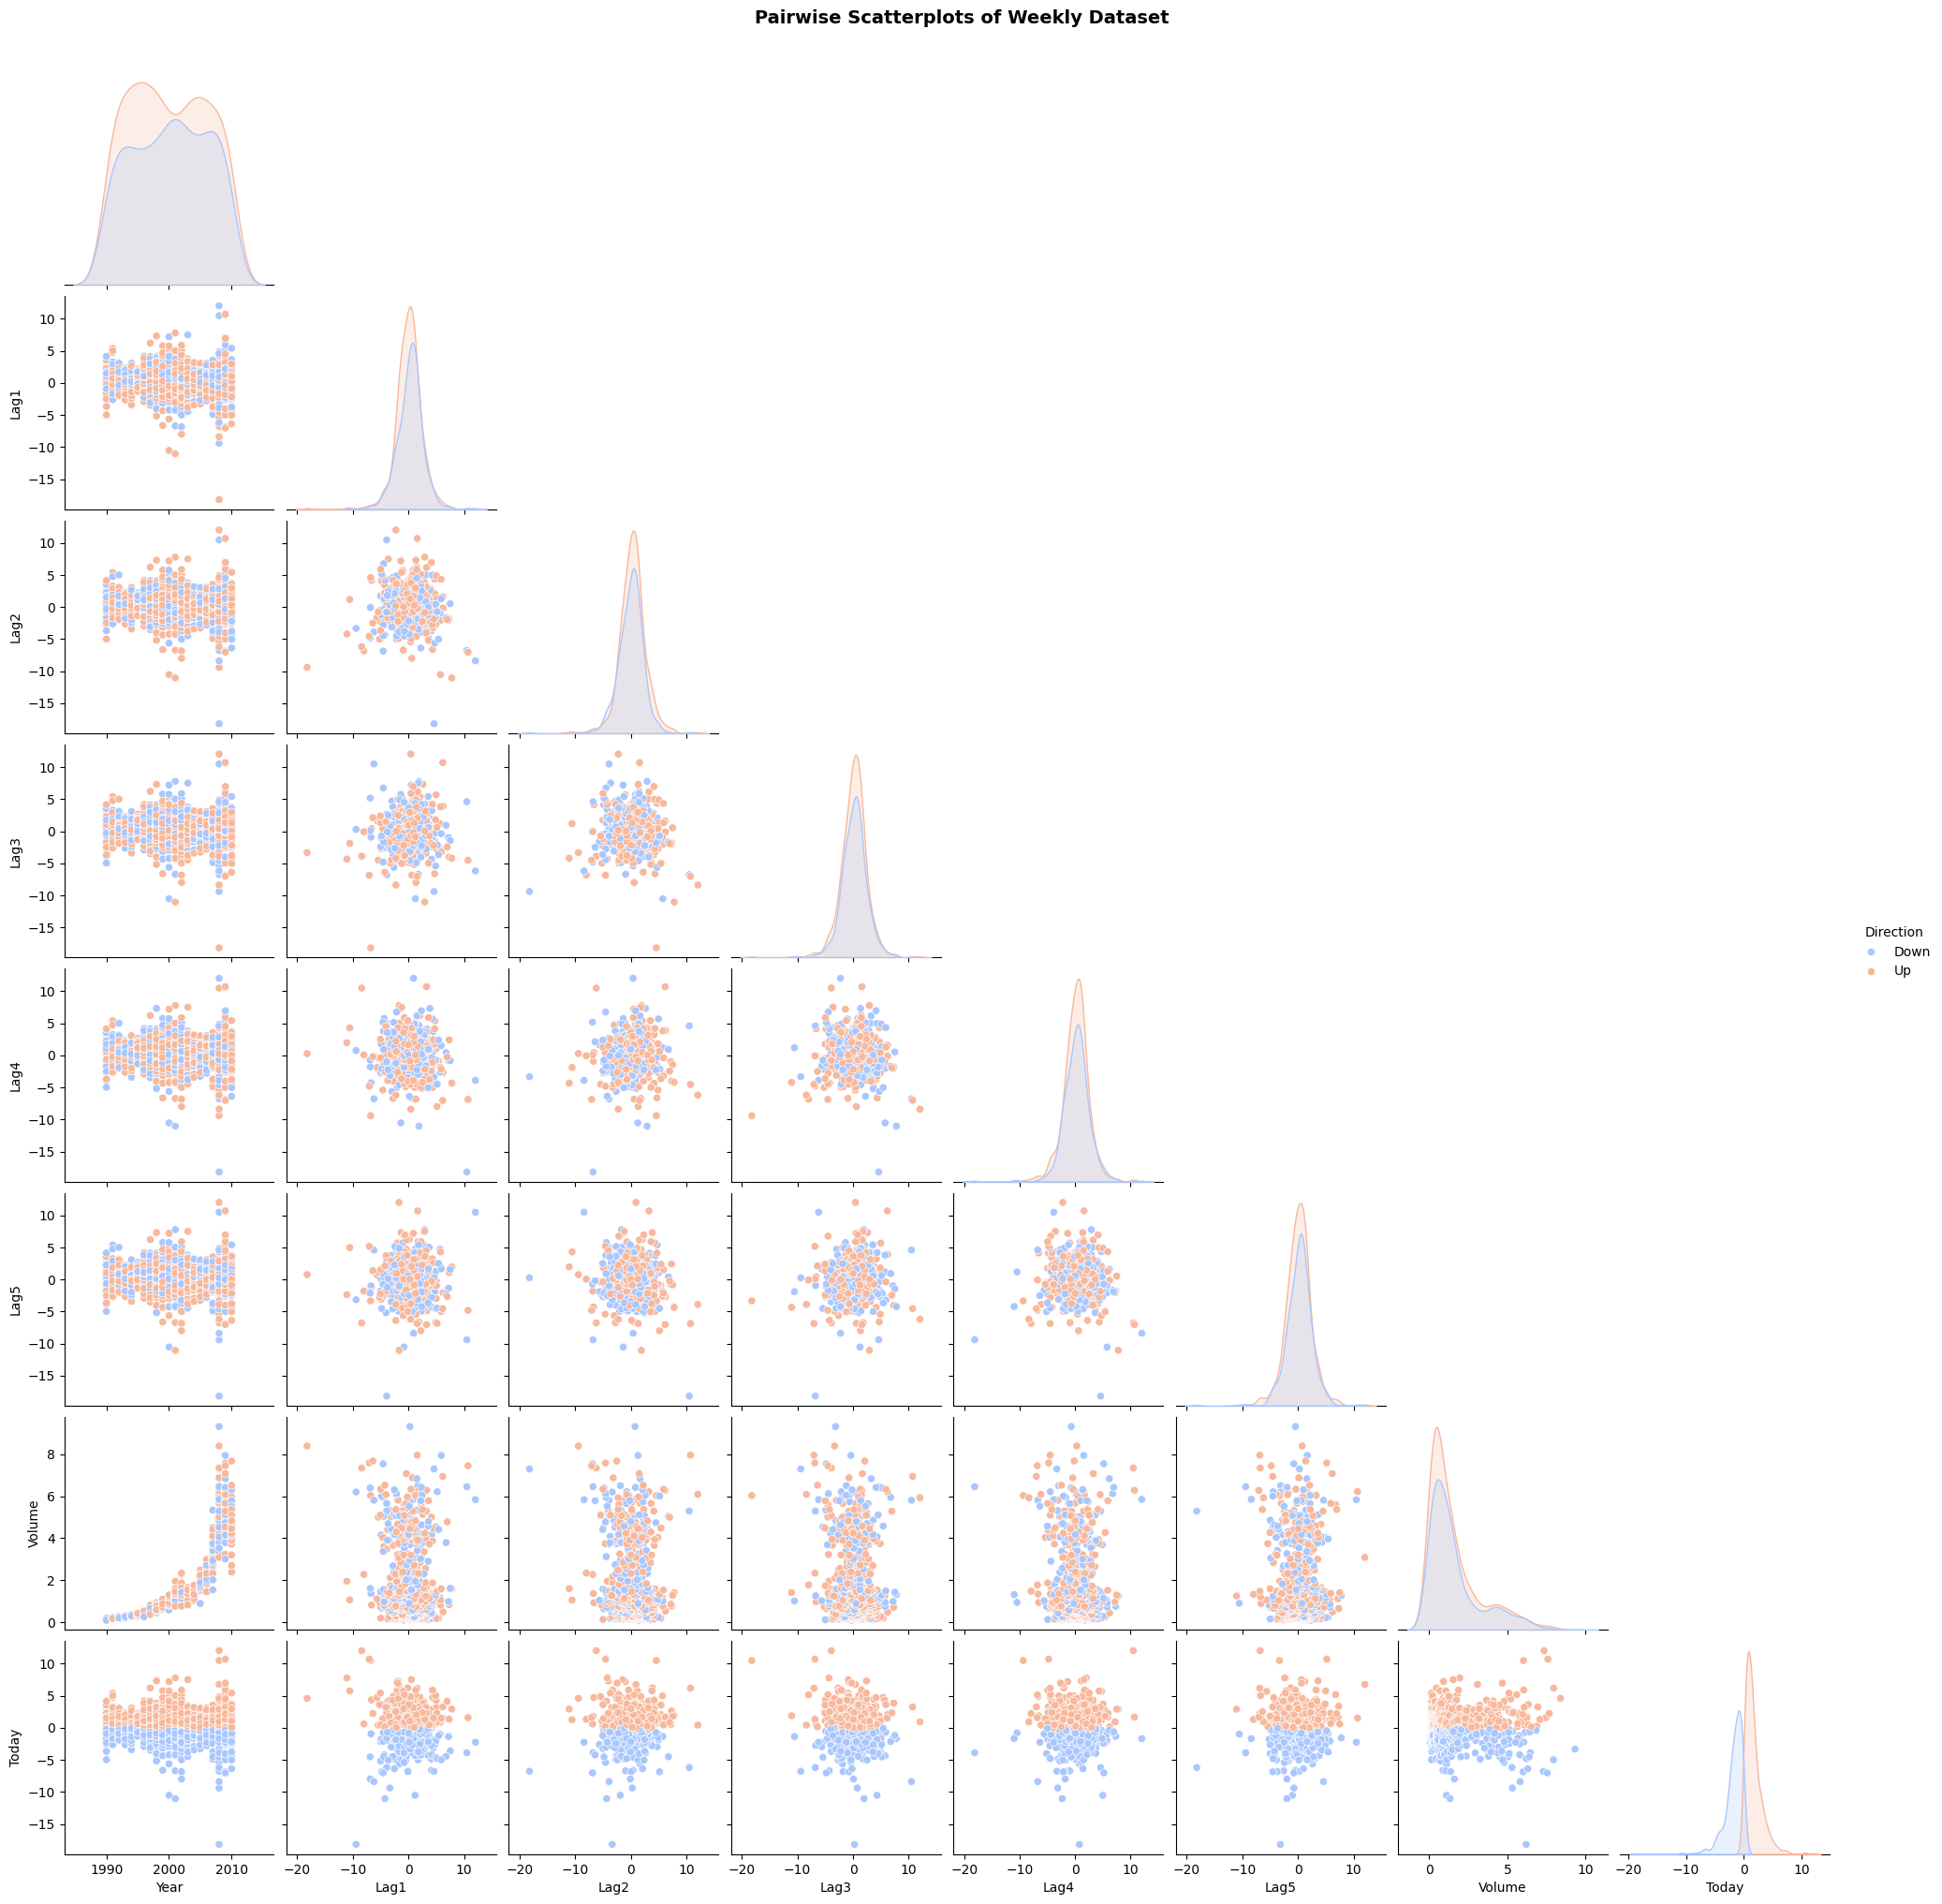

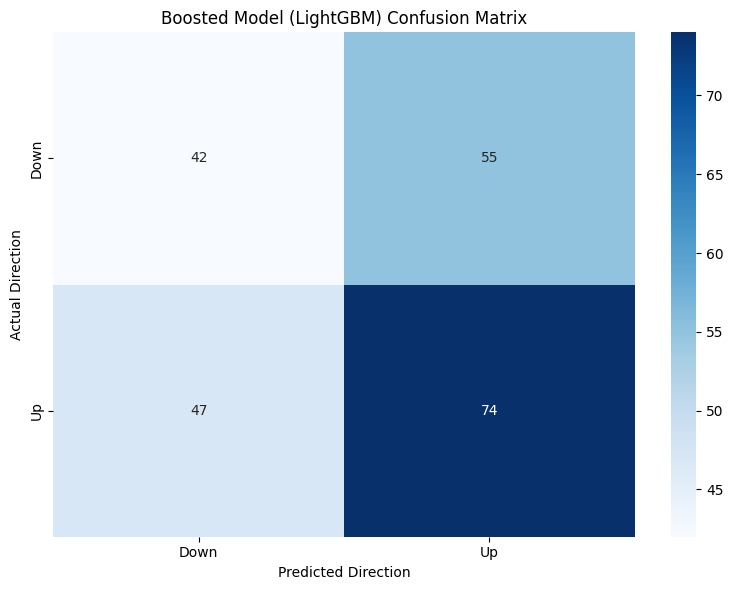

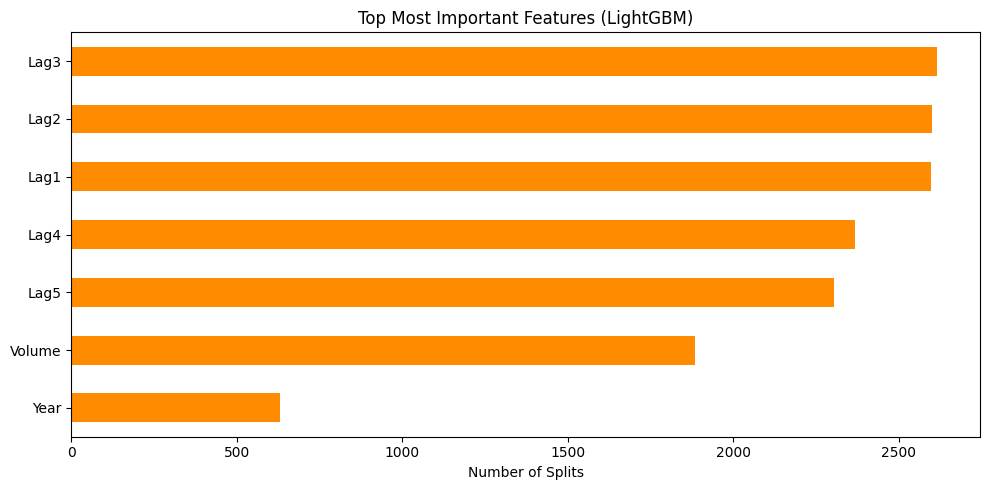


--- Preparing Data for Bagging Model ---
Training Bagging Model...

Bagging Model Validation Accuracy: 0.5550
Bagging Model Out-of-Bag (OOB) Score: 0.5442

--- Classification Report (Bagging) ---
              precision    recall  f1-score   support

        Down       0.50      0.40      0.45        97
          Up       0.59      0.68      0.63       121

    accuracy                           0.56       218
   macro avg       0.54      0.54      0.54       218
weighted avg       0.55      0.56      0.55       218



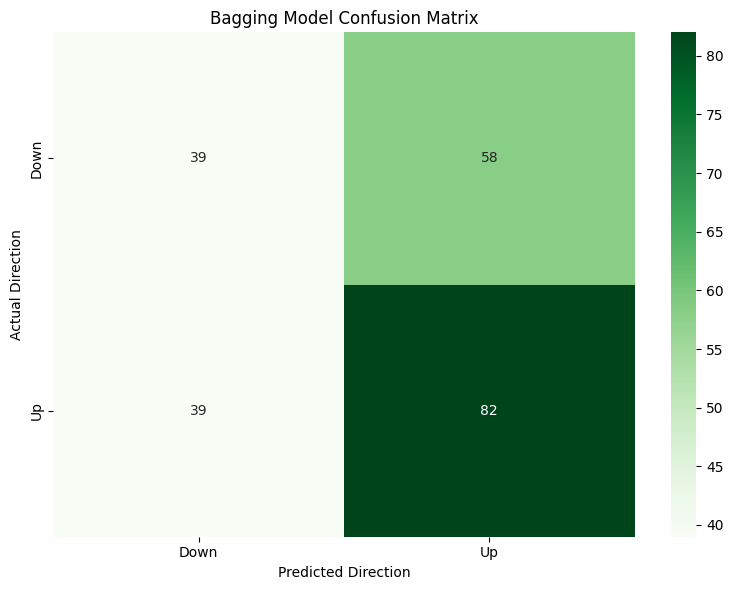

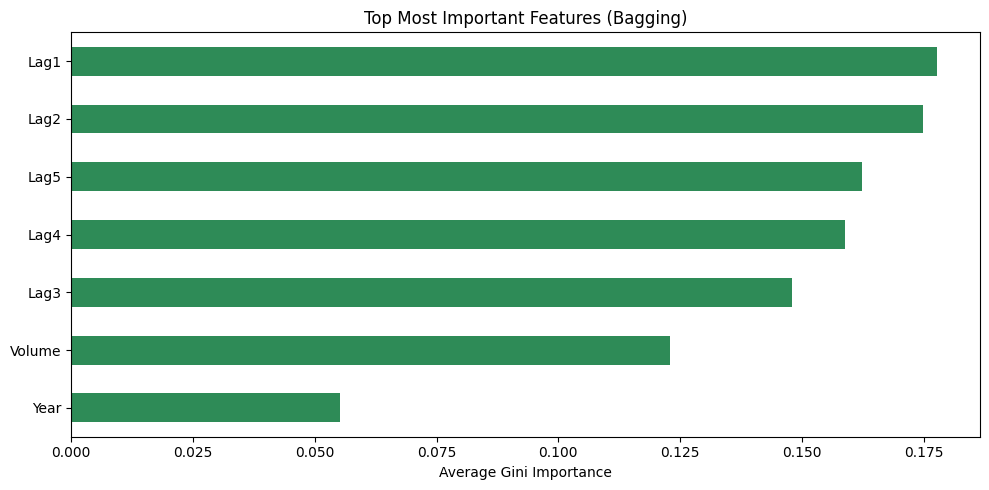


--- Preparing Data for Random Forest Model ---
Training Random Forest Model...

Random Forest Validation Accuracy: 0.5550
Random Forest Out-of-Bag (OOB) Score: 0.5499

--- Classification Report (Random Forest) ---
              precision    recall  f1-score   support

        Down       0.50      0.39      0.44        97
          Up       0.58      0.69      0.63       121

    accuracy                           0.56       218
   macro avg       0.54      0.54      0.54       218
weighted avg       0.55      0.56      0.55       218



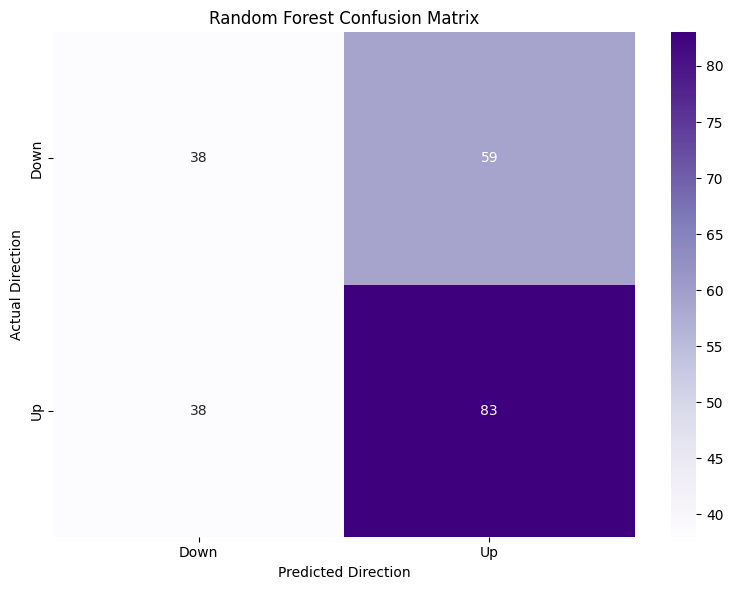

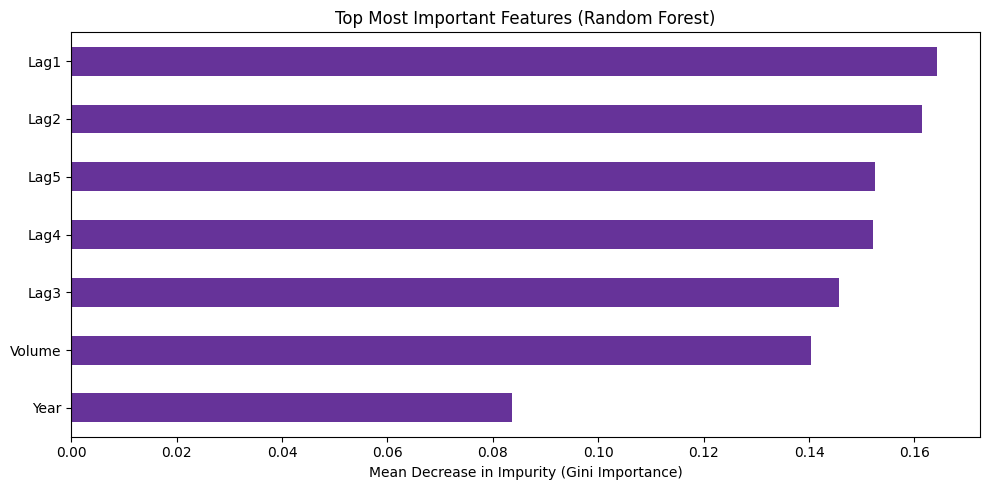


--- Preparing Data for BART Model ---
Training BART Model (this may take a few seconds)...

BART Model Validation Accuracy: 0.5642

--- Classification Report (BART) ---
              precision    recall  f1-score   support

        Down       0.52      0.27      0.35        97
          Up       0.58      0.80      0.67       121

    accuracy                           0.56       218
   macro avg       0.55      0.53      0.51       218
weighted avg       0.55      0.56      0.53       218



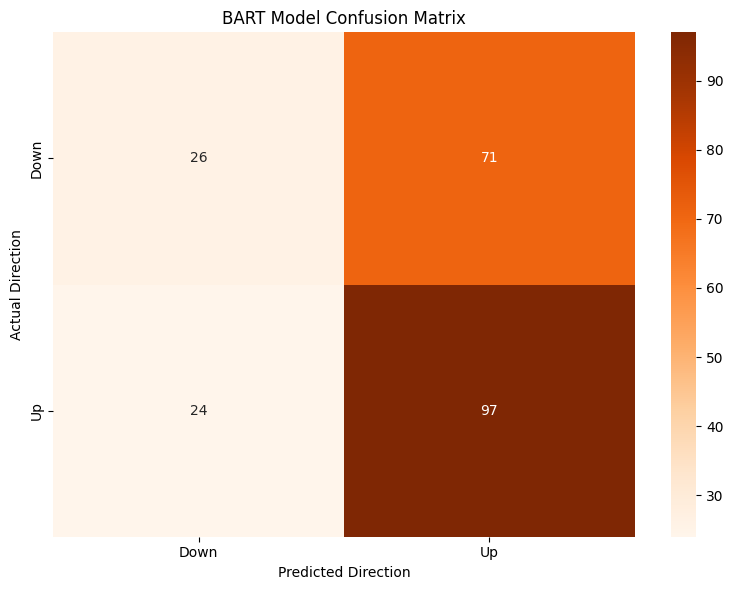

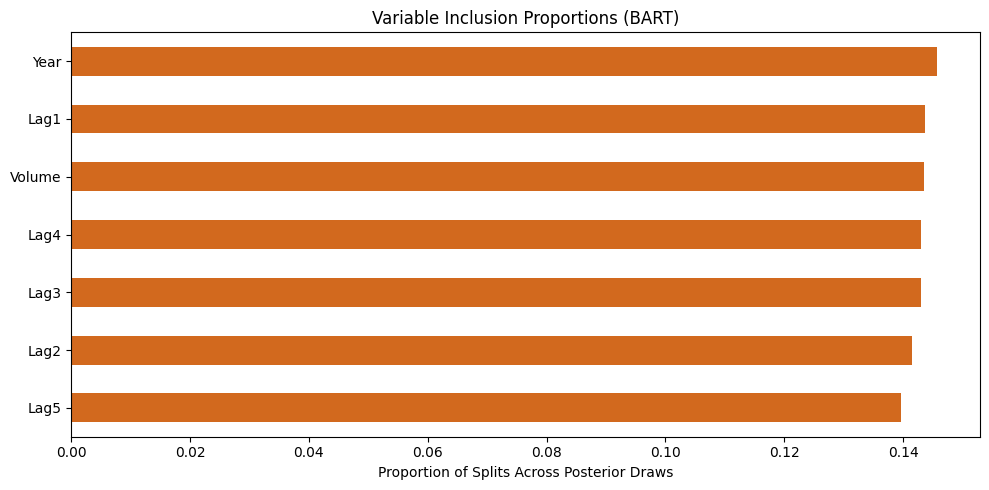

In [10]:
# Section A: Load the "Weekly" dataset and show some EDA.

# 1,089 weekly observations of percentage returns for the S&P 500 stock index across 21 years,
# spanning from the beginning of 1990 to the end of 2010. The raw index values were originally
# sourced from Yahoo Finance, converted into weekly percentage returns, and lagged.

!pip install ISLP

from ISLP import load_data

# 1. Load the Weekly dataset
Weekly = load_data('Weekly')

# 2. Display the first few rows of the dataframe
print(Weekly.head())


# 3. Produce some numerical and graphical summaries of the Weekly data.

import matplotlib.pyplot as plt
import seaborn as sns

# 4. Generate a Red-White-Blue Correlation Matrix
# Select only numerical columns for correlation calculation
numeric_cols = Weekly.select_dtypes(include=['number'])
corr_matrix = numeric_cols.corr()

plt.figure(figsize=(10, 8))
# 'RdBu_r' gives a reversed Red-Blue palette so positive correlation is Red,
# zero is White, and negative correlation is Blue.
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='RdBu_r',
    vmin=-1,
    vmax=1,
    center=0,
    fmt=".3f",
    linewidths=0.5
)
plt.title('Correlation Matrix (Weekly Dataset)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# 5. Generate All Pairwise Scatterplots
# We color-code the points by 'Direction' (Up/Down) to match standard ISLP lab style
sns.pairplot(Weekly, hue='Direction', palette='coolwarm', corner=True)
plt.suptitle('Pairwise Scatterplots of Weekly Dataset', y=1.02, fontsize=14, fontweight='bold')
# plt.show() is handled automatically by seaborn's pairplot grid display


# Section B: Use the full data set to use boosting, bagging, random forest, and BART
# to predict Direction as the response using the other variables
# as predictors. Use the summary function to print the results.

# 1. Boosting

# Core Idea: Instead of building trees independently in parallel, Boosting builds trees sequentially. Each new tree is shallow (a "weak learner") and is specifically trained to predict the residuals (errors) left behind by the combination of all previous trees.
# Strength: Each tree acts as a small corrective step scaled by a small learning_rate (\(\lambda \)), allowing the ensemble to slowly chip away at bias and capture subtle patterns in the data.
# Limitation: Because each tree chases the remaining errors, Boosting can eventually start fitting random noise if you add too many trees (n_estimators) without proper tuning.

import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from lightgbm import LGBMClassifier

print("\n--- Preparing Data for Boosted Model (LightGBM) ---")

# a. Separate features (X) and target (y)
# Drop 'Direction' (target) and 'Today' (causes data leakage since Direction is derived from Today)
X = Weekly.drop(columns=['Direction', 'Today'], errors='ignore')
y = Weekly['Direction']

# b. Encode the target classes ('Down' -> 0, 'Up' -> 1)
target_encoder = LabelEncoder()
y_encoded = target_encoder.fit_transform(y)

# c. One-hot encode categorical text features if any exist
X_encoded = pd.get_dummies(X, drop_first=True)

# d. Split into training (80%) and validation (20%) sets
X_train, X_val, y_train, y_val = train_test_split(
    X_encoded,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

# e. Initialize and train the Boosted Model
boosted_model = LGBMClassifier(
    n_estimators=500,          # Builds up to 500 sequential trees
    learning_rate=0.05,        # Small step size so each tree gently corrects prior errors
    num_leaves=31,             # Controls tree complexity
    colsample_bytree=0.8,      # Uses 80% of features per tree to prevent overfitting
    subsample=0.8,             # Uses 80% of rows per tree
    random_state=42,
    n_jobs=-1,
    verbose=-1                 # Keeps console output clean
)

print("Training LightGBM Boosted Model...")
boosted_model.fit(X_train, y_train)

# f. Make predictions and evaluate
y_pred = boosted_model.predict(X_val)

accuracy = accuracy_score(y_val, y_pred)
print(f"\nBoosted Model (LightGBM) Validation Accuracy: {accuracy:.4f}")

print("\n--- Classification Report ---")
print(classification_report(
    y_val,
    y_pred,
    target_names=target_encoder.classes_
))

# g. Plot the Confusion Matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_val, y_pred)
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=target_encoder.classes_,
    yticklabels=target_encoder.classes_
)
plt.title('Boosted Model (LightGBM) Confusion Matrix')
plt.ylabel('Actual Direction')
plt.xlabel('Predicted Direction')
plt.tight_layout()
plt.show()

# h. Display Top Most Important Features
feature_importances = pd.Series(boosted_model.feature_importances_, index=X_train.columns)
plt.figure(figsize=(10, 5))
feature_importances.nlargest(10).sort_values().plot(kind='barh', color='darkorange')
plt.title('Top Most Important Features (LightGBM)')
plt.xlabel('Number of Splits')
plt.tight_layout()
plt.show()


# 2. Bagging Model

# Core Idea: Create many random copies of the training dataset by sampling with replacement (bootstrap samples), grow a full, deep decision tree on each copy, and average their predictions (or take a majority vote for classification).
# Strength: Individual deep decision trees have low bias but high variance. Averaging hundreds of independent trees cancels out their individual errors and dramatically stabilizes predictions.
# Limitation: Because every tree considers all predictors at every split, one or two dominant features will sit at the top of almost every tree. As a result, the trees look very similar (high correlation), which limits how much variance averaging can remove.


from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

print("\n--- Preparing Data for Bagging Model ---")

# Note: Reusing X_train, X_val, y_train, y_val, and target_encoder from Section 1

# a. Initialize and train the Bagging Model
# Bagging uses Decision Trees as base estimators and trains each on a random bootstrap sample
bagging_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=500,          # Builds 500 independent decision trees
    max_samples=1.0,           # Uses 100% of training rows (with replacement) per tree
    max_features=1.0,          # Uses all features (key distinction between Bagging and Random Forest)
    bootstrap=True,            # Enables bootstrap sampling
    oob_score=True,            # Computes Out-of-Bag accuracy estimate
    random_state=42,
    n_jobs=-1
)

print("Training Bagging Model...")
bagging_model.fit(X_train, y_train)

# b. Make predictions and evaluate
y_pred_bag = bagging_model.predict(X_val)

accuracy_bag = accuracy_score(y_val, y_pred_bag)
print(f"\nBagging Model Validation Accuracy: {accuracy_bag:.4f}")
print(f"Bagging Model Out-of-Bag (OOB) Score: {bagging_model.oob_score_:.4f}")

print("\n--- Classification Report (Bagging) ---")
print(classification_report(
    y_val,
    y_pred_bag,
    target_names=target_encoder.classes_
))

# c. Plot the Confusion Matrix
plt.figure(figsize=(8, 6))
cm_bag = confusion_matrix(y_val, y_pred_bag)
sns.heatmap(
    cm_bag,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=target_encoder.classes_,
    yticklabels=target_encoder.classes_
)
plt.title('Bagging Model Confusion Matrix')
plt.ylabel('Actual Direction')
plt.xlabel('Predicted Direction')
plt.tight_layout()
plt.show()

# d. Display Feature Importances (averaged across all 500 trees)
bag_importances = pd.Series(
    sum(tree.feature_importances_ for tree in bagging_model.estimators_) / len(bagging_model.estimators_),
    index=X_train.columns
)
plt.figure(figsize=(10, 5))
bag_importances.nlargest(10).sort_values().plot(kind='barh', color='seagreen')
plt.title('Top Most Important Features (Bagging)')
plt.xlabel('Average Gini Importance')
plt.tight_layout()
plt.show()



# 3. Random Forest Model

# Core Idea: Random Forest improves directly on Bagging by adding one simple rule: at each split in a tree, the algorithm is only allowed to choose from a random subset of predictors (typically \(\sqrt{p}\) features for classification).
# Strength: Forcing trees to ignore the strongest predictor on many splits allows weaker, secondary predictors to play a role. This decorrelates the trees so that averaging them reduces variance much more effectively than standard Bagging.
# Limitation: Like Bagging, trees are grown independently without learning from the mistakes of earlier trees.

from sklearn.ensemble import RandomForestClassifier

print("\n--- Preparing Data for Random Forest Model ---")

# Note: Reusing X_train, X_val, y_train, y_val, and target_encoder from Section 1

# a. Initialize and train the Random Forest Model
# Unlike Bagging, Random Forest considers only a random subset of features at each split ('sqrt')
rf_model = RandomForestClassifier(
    n_estimators=500,          # Builds 500 independent decision trees
    max_features='sqrt',       # Key distinction: considers sqrt(p) features per split to decorrelate trees
    bootstrap=True,            # Enables bootstrap sampling
    oob_score=True,            # Computes Out-of-Bag accuracy estimate
    random_state=42,
    n_jobs=-1
)

print("Training Random Forest Model...")
rf_model.fit(X_train, y_train)

# b. Make predictions and evaluate
y_pred_rf = rf_model.predict(X_val)

accuracy_rf = accuracy_score(y_val, y_pred_rf)
print(f"\nRandom Forest Validation Accuracy: {accuracy_rf:.4f}")
print(f"Random Forest Out-of-Bag (OOB) Score: {rf_model.oob_score_:.4f}")

print("\n--- Classification Report (Random Forest) ---")
print(classification_report(
    y_val,
    y_pred_rf,
    target_names=target_encoder.classes_
))

# c. Plot the Confusion Matrix
plt.figure(figsize=(8, 6))
cm_rf = confusion_matrix(y_val, y_pred_rf)
sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Purples',
    xticklabels=target_encoder.classes_,
    yticklabels=target_encoder.classes_
)
plt.title('Random Forest Confusion Matrix')
plt.ylabel('Actual Direction')
plt.xlabel('Predicted Direction')
plt.tight_layout()
plt.show()

# d. Display Most Important Features
rf_importances = pd.Series(rf_model.feature_importances_, index=X_train.columns)
plt.figure(figsize=(10, 5))
rf_importances.nlargest(10).sort_values().plot(kind='barh', color='rebeccapurple')
plt.title('Top Most Important Features (Random Forest)')
plt.xlabel('Mean Decrease in Impurity (Gini Importance)')
plt.tight_layout()
plt.show()


# 4. BART Model (Bayesian Additive Regression Trees)

# Core Idea: BART is a Bayesian sum-of-trees model. Like Boosting, the final prediction is the sum of many small trees, where each tree explains only a tiny portion of the outcome. However, instead of optimizing trees via gradient descent, BART uses Markov Chain Monte Carlo (MCMC) sampling to repeatedly update the tree structures and leaf values from a posterior probability distribution.
# Strength: BART places strict regularizing priors on tree depth and leaf predictions so no single tree can dominate, preventing overfitting without requiring heavy hyperparameter tuning. Because it generates hundreds of posterior draws, BART naturally produces credible intervals (uncertainty estimates) for every prediction.
# Limitation: MCMC sampling is computationally slower on very large datasets compared to modern gradient boosting libraries like LightGBM.

from ISLP.bart import BART

print("\n--- Preparing Data for BART Model ---")

# Note: Reusing X_train, X_val, y_train, y_val, and target_encoder from Section 1
# ISLP's BART expects NumPy arrays (or numeric matrices) rather than pandas DataFrames
X_train_bart = X_train.to_numpy(dtype=float)
X_val_bart = X_val.to_numpy(dtype=float)

# a. Initialize and train the BART Model
# BART builds a sum of trees updated via MCMC / Particle Gibbs sampling
bart_model = BART(
    num_trees=200,      # Number of trees in the additive ensemble
    burnin=100,         # Initial MCMC iterations discarded for stabilization
    ndraw=100,          # Posterior draws retained after burn-in
    random_state=42,
    n_jobs=-1
)

print("Training BART Model (this may take a few seconds)...")
bart_model.fit(X_train_bart, y_train)

# b. Make predictions and evaluate
# BART outputs continuous posterior mean predictions (probabilities); threshold at 0.5 for class labels
y_prob_bart = bart_model.predict(X_val_bart)
y_pred_bart = (y_prob_bart >= 0.5).astype(int)

accuracy_bart = accuracy_score(y_val, y_pred_bart)
print(f"\nBART Model Validation Accuracy: {accuracy_bart:.4f}")

print("\n--- Classification Report (BART) ---")
print(classification_report(
    y_val,
    y_pred_bart,
    target_names=target_encoder.classes_
))

# c. Plot the Confusion Matrix
plt.figure(figsize=(8, 6))
cm_bart = confusion_matrix(y_val, y_pred_bart)
sns.heatmap(
    cm_bart,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=target_encoder.classes_,
    yticklabels=target_encoder.classes_
)
plt.title('BART Model Confusion Matrix')
plt.ylabel('Actual Direction')
plt.xlabel('Predicted Direction')
plt.tight_layout()
plt.show()

# d. Display Variable Inclusion Proportions (Feature Importance equivalent for BART)
# ISLP's BART automatically records split counts per draw in .variable_inclusion_
mean_inclusions = bart_model.variable_inclusion_.mean(0)
bart_importances = pd.Series(
    mean_inclusions / mean_inclusions.sum(),
    index=X_train.columns
)

plt.figure(figsize=(10, 5))
bart_importances.nlargest(10).sort_values().plot(kind='barh', color='chocolate')
plt.title('Variable Inclusion Proportions (BART)')
plt.xlabel('Proportion of Splits Across Posterior Draws')
plt.tight_layout()
plt.show()


